# 09 — Receptor competence: do PBMCs respond to ligands whose receptors they lack?

**Finding:** The seven receptor-poor ligands produce no PBMC response above well-to-well noise while most receptor-rich ligands respond in nearly every cell type, and the 06 model predicts near-zero for the receptor-poor ligands only because it predicts near-zero for *every* unseen ligand, including IFN-γ, whose observed response is 4× the noise floor.

---

**Question.** PBMCs barely express receptors for growth factors like EGF, HGF or VEGF, so those ligands should do
little to them. Is the observed response magnitude explained by cognate-receptor expression? And does the CellFlow
model from 06 respect that, or does it predict sizeable effects for ligands whose receptors are absent?

**Ligand groups**

| group | ligands |
|---|---|
| receptor-poor in PBMC | EGF, FGF-beta, HGF, IGF-1, VEGF, GDNF, PSPN |
| receptor-rich in PBMC | GM-CSF, IL-15, TNF-alpha, IFN-gamma, IL-4, IL-2 |

**Data**
* **Responses (parts 1–2): the full dataset** (`pbmc_parse.h5ad`, HF `theislab/cellflow-datasets`, 12 donors, 2,000 HVGs,
  raw counts), because 8 of the 13 ligands are not in `pbmc_subset.h5ad`. Only the 13 ligands + PBS are read (chunked,
  on a compute node).
* **Receptor expression (part 3): Parse's PBS pseudobulks** (`data/cellflow/parse_pseudobulk_PBS/`, 24 files taken out
  of `pseudobulks_20260203.zip` with HTTP range requests, CC BY-NC 4.0). The HF matrix has only 4 of the 19 receptor
  genes, because receptors are rarely highly variable. The pseudobulks are per-donor raw-count sums over all 40,352
  genes in PBS cells.
* **Model (part 4):** `models/06_baseline_CellFlow.pkl` (notebook 01 saved no model; 06 is the only trained one).

**Methods, with the choices the request left open**
* Response is computed per **donor × ligand × cell type**, against **that donor's PBS cells of the same cell type**,
  then summarised as the **median over donors**.
* Wilcoxon DE counts grow with cell number, so both sides are **subsampled to the same n = min(n_ligand, n_PBS, 500)**
  cells (`random_state=0`). Pairs with n < 30 are skipped. DE uses `scanpy.tl.rank_genes_groups(method="wilcoxon")` on
  log1p(CP10k) with BH FDR < 0.05 and |log2FC| > 0.5.
* **Noise floors.** In this experiment each cytokine × donor sits in **one** barcoding well (`bc1_well`), while PBS
  spans **6 wells** per donor. So a ligand-vs-PBS comparison always includes well-to-well technical variation. Two
  floors, same statistics, same n:
  * *random floor*: two disjoint random halves of a donor's PBS cells (no well difference, so a lower bound);
  * **well floor** (the relevant null): one PBS well vs that donor's other PBS wells, i.e. exactly the ligand-vs-PBS
    design with no ligand. A "near-zero" response means "indistinguishable from the well floor".
* Energy distance: `cellflow.metrics.compute_e_distance` in a 50-PC space fitted on a balanced subsample of the loaded
  cells (all 13 ligands + PBS, all donors).
* Receptor score per ligand × cell type = mean over the listed subunits of log1p(CPM) in PBS pseudobulks, averaged over
  donors. Mapping: EGF→EGFR; FGF-beta→FGFR1; HGF→MET; IGF-1→IGF1R; VEGF→KDR; GDNF→RET+GFRA1; PSPN→RET+GFRA4;
  GM-CSF→CSF2RA+CSF2RB; IL-15→IL2RG+IL2RB+IL15RA; TNF-alpha→TNFRSF1A+TNFRSF1B; IFN-gamma→IFNGR1+IFNGR2; IL-4→IL4R;
  IL-2→IL2RA+IL2RB. **GFRA4 is not in the pseudobulk gene annotation, so PSPN is scored on RET alone.**
  A sensitivity version uses the **minimum** subunit (a heteromeric receptor is only as available as its scarcest chain).
* Part 4 compares observed and predicted responses **in the model's own 100-PC space**, for the 4 donors the model was
  trained on. For each donor, 2,000 PBS cells are the model's source and a **disjoint** set of PBS cells is the reference,
  so a model that predicts "no change" scores the random floor. The well floor (one PBS well vs the others) is the
  observed-data analogue of "a ligand that does nothing".

In [1]:
import warnings
warnings.simplefilter("ignore")
import os
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")

import gc
import glob
import time
import numpy as np
import pandas as pd
import scipy.sparse as sp
import h5py
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, pearsonr
from cellflow.metrics import compute_e_distance

FULL_PATH = "/fast/AG_Bunina/Pavel_1/data/cellflow/hf_cache/hub/datasets--theislab--cellflow-datasets/snapshots/4b235c9a1e0073c95211c6ef6257db184fc83f71/pbmc_parse.h5ad"
PSEUDOBULK_DIR = "/fast/AG_Bunina/Pavel_1/data/cellflow/parse_pseudobulk_PBS"
MODEL_PATH = "../models/06_baseline_CellFlow.pkl"
OUT_DIR = "../models"
SEED = 0
N_MAX, N_MIN = 500, 30
FDR, LFC = 0.05, 0.5
N_PCS = 50

POOR = ["EGF", "FGF-beta", "HGF", "IGF-1", "VEGF", "GDNF", "PSPN"]
RICH = ["GM-CSF", "IL-15", "TNF-alpha", "IFN-gamma", "IL-4", "IL-2"]
LIGANDS = POOR + RICH
GROUP = {**{l: "receptor-poor" for l in POOR}, **{l: "receptor-rich" for l in RICH}}
RECEPTORS = {
    "EGF": ["EGFR"], "FGF-beta": ["FGFR1"], "HGF": ["MET"], "IGF-1": ["IGF1R"], "VEGF": ["KDR"],
    "GDNF": ["RET", "GFRA1"], "PSPN": ["RET", "GFRA4"],
    "GM-CSF": ["CSF2RA", "CSF2RB"], "IL-15": ["IL2RG", "IL2RB", "IL15RA"], "TNF-alpha": ["TNFRSF1A", "TNFRSF1B"],
    "IFN-gamma": ["IFNGR1", "IFNGR2"], "IL-4": ["IL4R"], "IL-2": ["IL2RA", "IL2RB"],
}
GROUP_COLORS = {"receptor-poor": "#3F8AA6", "receptor-rich": "#B12F8C"}

## 1. Load the 13 ligands + PBS from the full dataset

In [2]:
t0 = time.perf_counter()
with h5py.File(FULL_PATH, "r") as f:
    def cat(col):
        g = f["obs"][col]
        return pd.Categorical.from_codes(g["codes"][:], g["categories"][:].astype(str))
    obs_all = pd.DataFrame({c: cat(c) for c in ["cytokine", "donor", "cell_type", "bc1_well"]})
    obs_all.index = f["obs"]["_index"][:].astype(str)
    var_names = f["var"]["_index"][:].astype(str)
    keep = np.flatnonzero(obs_all["cytokine"].isin(LIGANDS + ["PBS"]).to_numpy())

    # read X in row chunks, keeping only the wanted rows (sequential reads of an uncompressed CSR)
    indptr = f["X"]["indptr"][:]
    blocks, CH = [], 500_000
    for s in range(0, len(obs_all), CH):
        e = min(s + CH, len(obs_all))
        rows = keep[(keep >= s) & (keep < e)]
        if len(rows) == 0:
            continue
        lo, hi = indptr[s], indptr[e]
        blk = sp.csr_matrix((f["X"]["data"][lo:hi], f["X"]["indices"][lo:hi], indptr[s:e + 1] - lo),
                            shape=(e - s, len(var_names)))
        blocks.append(blk[rows - s])

adata = ad.AnnData(X=sp.vstack(blocks).tocsr(), obs=obs_all.iloc[keep].copy(), var=pd.DataFrame(index=var_names))
del blocks, obs_all
gc.collect()
for c in ["cytokine", "donor", "cell_type", "bc1_well"]:
    adata.obs[c] = adata.obs[c].cat.remove_unused_categories()
print(f"loaded {adata.n_obs:,} cells × {adata.n_vars} genes in {time.perf_counter() - t0:.0f} s")
assert set(LIGANDS) <= set(adata.obs["cytokine"].unique()), set(LIGANDS) - set(adata.obs["cytokine"].unique())
X_head = adata.X[:1000].toarray()
assert np.allclose(X_head, np.round(X_head)), "expected raw counts"

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.obs["cytokine"].value_counts().to_frame("cells")

loaded 1,903,685 cells × 2000 genes in 12 s


,cells
cytokine,
PBS,629701
IL-15,113033
IL-4,110998
TNF-alpha,104866
EGF,104268
GM-CSF,100521
IL-2,99732
IFN-gamma,99063
IGF-1,95842


In [3]:
counts = adata.obs.groupby(["cytokine", "cell_type"], observed=True).size().unstack(fill_value=0)
counts.loc[LIGANDS + ["PBS"]]

cell_type,B Intermediate/Memory,B Naive,CD4 Memory,CD4 Naive,CD8 Memory,CD8 Naive,CD14 Mono,CD16 Mono,HSPC,ILC,MAIT,NK,NK CD56bright,NKT,Plasmablast,Treg,cDC,pDC
cytokine,,,,,,,,,,,,,,,,,,
EGF,3540,6713,23739,20012,7920,7135,17021,2650,205,96,3746,5480,1296,1593,77,1738,1133,174
FGF-beta,2884,5741,20852,16689,6915,6045,15240,2248,164,61,2986,5020,1187,1447,64,1559,1048,210
HGF,2955,5940,21843,15832,6781,5721,15414,2291,140,76,3228,4579,1147,1242,49,1509,1027,159
IGF-1,3114,5988,25191,15799,7408,6124,15633,2463,190,75,3434,5019,1180,1397,64,1488,1121,154
VEGF,2790,5459,19632,15205,7171,5708,13950,2200,157,63,3205,4402,998,1562,46,1429,951,81
GDNF,2892,5451,21067,15694,7342,5876,14324,2058,165,88,3203,4867,1185,1783,44,1555,837,104
PSPN,3115,6239,22660,15880,7493,6154,14069,2307,160,88,3341,4964,1138,1639,55,1497,898,127
GM-CSF,3601,6408,20737,20984,7075,6966,18736,2168,201,116,2505,5167,1160,1280,58,1653,1346,360
IL-15,5011,7810,25110,24647,8457,8066,15172,2634,204,78,2324,4058,3506,748,77,3112,1691,328


### PCA space for energy distance

50 PCs fitted on a balanced subsample (up to 20,000 cells per ligand and PBS), then all cells are projected.

In [4]:
fit_idx = np.concatenate([
    np.random.default_rng(SEED).choice(np.flatnonzero(adata.obs["cytokine"].to_numpy() == c),
                                       size=min(20_000, int((adata.obs["cytokine"] == c).sum())), replace=False)
    for c in LIGANDS + ["PBS"]
])
fit = adata[np.sort(fit_idx)].copy()
sc.pp.pca(fit, n_comps=N_PCS, random_state=SEED)
gene_mean = np.asarray(fit.X.mean(axis=0)).ravel()
PCs = fit.varm["PCs"]
del fit
gc.collect()
adata.obsm["X_pca50"] = np.asarray(adata.X @ PCs) - gene_mean @ PCs
adata.obsm["X_pca50"].shape

(1903685, 50)

## 2. Response magnitude per donor × ligand × cell type

For each triple: equal-size subsamples of ligand and PBS cells, Wilcoxon DE count, and energy distance. PBS-vs-PBS
floor on two disjoint PBS halves of the same n.

In [5]:
def response(X_a, X_b, P_a, P_b):
    # Wilcoxon DE count (a vs b) and energy distance between the two groups
    tmp = ad.AnnData(X=sp.vstack([X_a, X_b]).tocsr(),
                     obs=pd.DataFrame({"g": pd.Categorical(["a"] * X_a.shape[0] + ["b"] * X_b.shape[0])}))
    tmp.uns["log1p"] = {"base": None}
    sc.tl.rank_genes_groups(tmp, "g", groups=["a"], reference="b", method="wilcoxon", tie_correct=True)
    r = sc.get.rank_genes_groups_df(tmp, group="a")
    n_de = int(((r["pvals_adj"] < FDR) & (r["logfoldchanges"].abs() > LFC)).sum())
    return n_de, float(compute_e_distance(P_a, P_b))


obs = adata.obs
idx_by = obs.groupby(["cytokine", "donor", "cell_type"], observed=True).indices
well_arr = obs["bc1_well"].astype(str).to_numpy()
print("wells per cytokine x donor:", obs.groupby(["cytokine", "donor"], observed=True)["bc1_well"].nunique()
      .groupby(level="cytokine").max().to_dict())
rng = np.random.default_rng(SEED)
rows = []
t0 = time.perf_counter()
for donor in sorted(obs["donor"].unique()):
    for ct in sorted(obs["cell_type"].unique()):
        ctrl = idx_by.get(("PBS", donor, ct), np.array([], int))
        # PBS vs PBS floor: two disjoint halves
        n0 = min(len(ctrl) // 2, N_MAX)
        if n0 >= N_MIN:
            perm = rng.permutation(ctrl)
            a, b = perm[:n0], perm[n0:2 * n0]
            nde, ed = response(adata.X[a], adata.X[b], adata.obsm["X_pca50"][a], adata.obsm["X_pca50"][b])
            rows.append({"ligand": "PBS (floor)", "donor": donor, "cell_type": ct, "n": n0, "n_de": nde, "e_distance": ed})
        # PBS well vs the donor's other PBS wells (same design as ligand vs PBS, without a ligand)
        ctrl_wells = well_arr[ctrl]
        for w in np.unique(ctrl_wells):
            in_w, out_w = ctrl[ctrl_wells == w], ctrl[ctrl_wells != w]
            n = min(len(in_w), len(out_w), N_MAX)
            if n < N_MIN:
                continue
            a, b = rng.choice(in_w, n, replace=False), rng.choice(out_w, n, replace=False)
            nde, ed = response(adata.X[a], adata.X[b], adata.obsm["X_pca50"][a], adata.obsm["X_pca50"][b])
            rows.append({"ligand": "PBS well (floor)", "donor": donor, "cell_type": ct, "n": n, "n_de": nde,
                         "e_distance": ed, "well": w})
        for lig in LIGANDS:
            pert = idx_by.get((lig, donor, ct), np.array([], int))
            n = min(len(pert), len(ctrl), N_MAX)
            if n < N_MIN:
                continue
            a, b = rng.choice(pert, n, replace=False), rng.choice(ctrl, n, replace=False)
            nde, ed = response(adata.X[a], adata.X[b], adata.obsm["X_pca50"][a], adata.obsm["X_pca50"][b])
            rows.append({"ligand": lig, "donor": donor, "cell_type": ct, "n": n, "n_de": nde, "e_distance": ed})
print(f"{len(rows)} comparisons in {time.perf_counter() - t0:.0f} s")

resp_donor = pd.DataFrame(rows)
resp_donor["group"] = resp_donor["ligand"].map(GROUP).fillna("PBS floor")
resp_donor.to_csv(os.path.join(OUT_DIR, "09_response_per_donor.csv"), index=False)

# well floor: median over wells within donor first, so every donor counts once
resp_donor = pd.concat([
    resp_donor[resp_donor["ligand"] != "PBS well (floor)"],
    resp_donor[resp_donor["ligand"] == "PBS well (floor)"].groupby(["ligand", "donor", "cell_type"], as_index=False)
    .agg(n=("n", "median"), n_de=("n_de", "median"), e_distance=("e_distance", "median"), group=("group", "first")),
], ignore_index=True)
resp = resp_donor.groupby(["ligand", "cell_type"], observed=True).agg(
    n_de=("n_de", "median"), e_distance=("e_distance", "median"), n_donors=("donor", "nunique"), median_n=("n", "median")
).reset_index()
resp["group"] = resp["ligand"].map(GROUP).fillna("PBS floor")

wells per cytokine x donor: {'EGF': 1, 'FGF-beta': 1, 'GDNF': 1, 'GM-CSF': 1, 'HGF': 1, 'IFN-gamma': 1, 'IGF-1': 1, 'IL-2': 1, 'IL-4': 1, 'IL-15': 1, 'PBS': 6, 'PSPN': 1, 'TNF-alpha': 1, 'VEGF': 1}


3260 comparisons in 118 s


### Response magnitude, median over donors

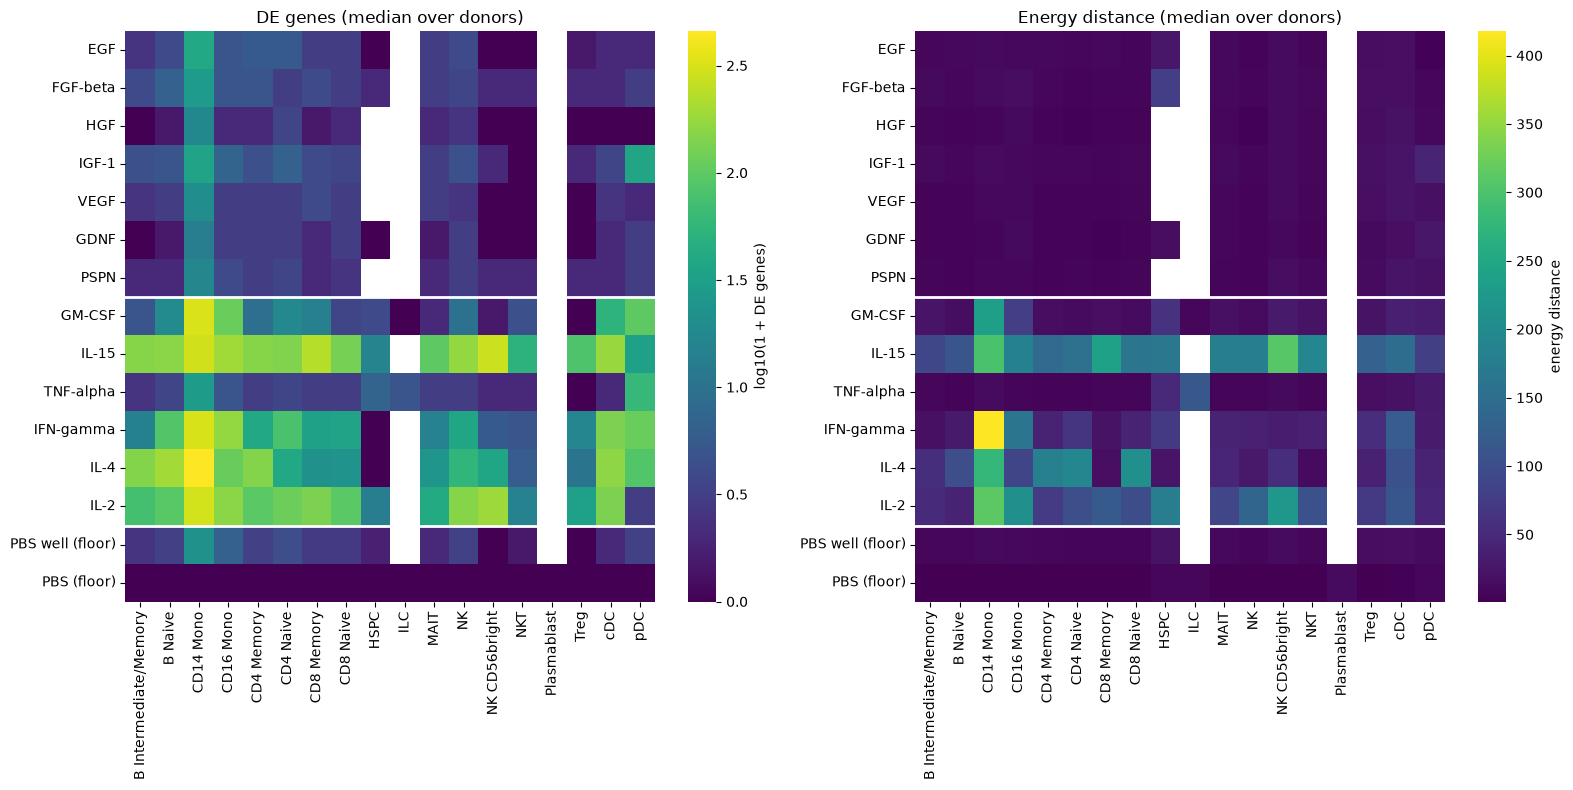

In [6]:
order = LIGANDS + ["PBS well (floor)", "PBS (floor)"]
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, metric, title in [(axes[0], "n_de", "DE genes (median over donors)"),
                          (axes[1], "e_distance", "Energy distance (median over donors)")]:
    m = resp.pivot(index="ligand", columns="cell_type", values=metric).reindex(order)
    sns.heatmap(np.log10(1 + m) if metric == "n_de" else m, ax=ax, cmap="viridis",
                cbar_kws={"label": "log10(1 + DE genes)" if metric == "n_de" else "energy distance"})
    ax.set_title(title); ax.set_xlabel(""); ax.set_ylabel("")
    ax.axhline(len(POOR), color="white", lw=2); ax.axhline(len(LIGANDS), color="white", lw=2)
plt.tight_layout()
plt.show()

In [7]:
floor_random = resp[resp["ligand"] == "PBS (floor)"].set_index("cell_type")[["n_de", "e_distance"]]
floor = resp[resp["ligand"] == "PBS well (floor)"].set_index("cell_type")[["n_de", "e_distance"]]
is_lig = ~resp["ligand"].str.startswith("PBS")
per_ligand = resp[is_lig].groupby(["group", "ligand"]).agg(
    median_DE=("n_de", "median"), max_DE=("n_de", "max"),
    median_edist=("e_distance", "median"), max_edist=("e_distance", "max"), n_cell_types=("cell_type", "nunique"))
above = resp[is_lig].join(floor, on="cell_type", rsuffix="_floor")
above["edist_above_floor"] = above["e_distance"] > 2 * above["e_distance_floor"]
above["de_above_floor"] = above["n_de"] > 2 * above["n_de_floor"] + 5
per_ligand["cell_types_edist>2×well floor"] = above.groupby(["group", "ligand"])["edist_above_floor"].sum()
per_ligand["cell_types_DE>2×well floor+5"] = above.groupby(["group", "ligand"])["de_above_floor"].sum()
for name, fl in [("random floor", floor_random), ("well floor", floor)]:
    print(f"{name}, median over cell types: DE genes {fl['n_de'].median()} | energy distance {fl['e_distance'].median():.3f}")
per_ligand.round(2)

random floor, median over cell types: DE genes 0.0 | energy distance 1.740
well floor, median over cell types: DE genes 1.75 | energy distance 9.170


median_DE  max_DE  median_edist  max_edist  \
group         ligand                                                  
receptor-poor EGF             2.00    38.0          9.54      26.64   
              FGF-beta        2.00    27.0         10.45      77.29   
              GDNF            1.00    12.0          6.19      26.15   
              HGF             0.50    16.5          7.23      19.39   
              IGF-1           3.50    36.0          9.85      42.22   
              PSPN            1.00    16.0          7.35      23.63   
              VEGF            2.00    19.0          7.00      23.00   
receptor-rich GM-CSF          8.00   320.5         21.77     233.75   
              IFN-gamma      35.00   314.5         40.83     417.66   
              IL-15         150.25   290.0        165.93     307.88   
              IL-2           94.00   298.0        103.14     312.53   
              IL-4           46.25   455.5         55.03     278.83   
              TNF-alpha       2.00    60.0          6.76     113.63   

                         n_cell_types  cell_types_edist>2×well floor  \
group         ligand                                                   
receptor-poor EGF                  16                              0   
              FGF-beta             16                              1   
              GDNF                 16                              0   
              HGF                  15                              0   
              IGF-1                15                              1   
              PSPN                 15                              0   
              VEGF                 15                              0   
receptor-rich GM-CSF               17                              9   
              IFN-gamma            16                             16   
              IL-15                16                             16   
              IL-2                 16                             16   
              IL-4                 16                             14   
              TNF-alpha            17                              2   

                         cell_types_DE>2×well floor+5  
group         ligand                                   
receptor-poor EGF                                   0  
              FGF-beta                              0  
              GDNF                                  0  
              HGF                                   0  
              IGF-1                                 1  
              PSPN                                  0  
              VEGF                                  0  
receptor-rich GM-CSF                                7  
              IFN-gamma                            13  
              IL-15                                16  
              IL-2                                 15  
              IL-4                                 14  
              TNF-alpha                             1

## 3. Receptor expression vs response magnitude

### Receptor matrix from Parse PBS pseudobulks

Cell-type names differ between the pseudobulks and the HF annotation. The mapping is by name, and the table checks
it by comparing PBS cell counts per donor. Parse notes that the release-time annotation (pseudobulks) may differ from
later annotations. Monocytes, DCs, HSPC and NK agree closely; the T-cell subsets less so.

In [8]:
CT_MAP = {
    "B Intermediate/Memory": "Intermediate_B_cell", "B Naive": "Naive_B_cell", "CD14 Mono": "CD14_Mono",
    "CD16 Mono": "CD16_Mono", "CD4 Memory": "CD4_Memory_T_cell_", "CD4 Naive": "CD4_Naive_T_cell_",
    "CD8 Memory": "CD8_Memory_T_cell", "CD8 Naive": "CD8_Naive_T_cell", "HSPC": "HSPC", "ILC": "ILC", "MAIT": "MAIT",
    "NK": "NK_CD56low", "NK CD56bright": "NK_CD56hi", "NKT": "NKT", "Plasmablast": "Plasmablast", "Treg": "Treg",
    "cDC": "cDC", "pDC": "pDC",
}
all_receptor_genes = sorted({g for gs in RECEPTORS.values() for g in gs})

pb_expr, pb_counts = {}, {}
for ct, pb_name in CT_MAP.items():
    pb = ad.read_h5ad(os.path.join(PSEUDOBULK_DIR, f"pbulk_{pb_name}_PBS.h5ad"))
    X = pb.X.toarray() if sp.issparse(pb.X) else np.asarray(pb.X)
    cpm = pd.DataFrame(X / X.sum(axis=1, keepdims=True) * 1e6, index=pb.obs["donor"].astype(str), columns=pb.var_names)
    present = [g for g in all_receptor_genes if g in cpm.columns]
    pb_expr[ct] = np.log1p(cpm[present])                     # donors x receptor genes
    pb_counts[ct] = pb.obs.set_index(pb.obs["donor"].astype(str))["psbulk_n_cells"]

missing_genes = sorted(set(all_receptor_genes) - set(next(iter(pb_expr.values())).columns))
print("receptor genes missing from pseudobulk annotation:", missing_genes)

hf_pbs_counts = adata.obs[adata.obs["cytokine"] == "PBS"].groupby(["cell_type", "donor"], observed=True).size().unstack()
check = pd.DataFrame({
    "HF PBS cells": hf_pbs_counts.sum(axis=1),
    "pseudobulk PBS cells": pd.Series({ct: pb_counts[ct].sum() for ct in CT_MAP}),
})
check["ratio"] = check["pseudobulk PBS cells"] / check["HF PBS cells"]
check["per-donor count corr"] = pd.Series({
    ct: np.corrcoef(hf_pbs_counts.loc[ct].reindex(pb_counts[ct].index).fillna(0), pb_counts[ct])[0, 1] for ct in CT_MAP})
check.round(2)

receptor genes missing from pseudobulk annotation: ['GFRA4']


,HF PBS cells,pseudobulk PBS cells,ratio,per-donor count corr
B Intermediate/Memory,21350.0,21772.0,1.02,0.91
B Naive,41445.0,41113.0,0.99,0.99
CD14 Mono,110999.0,110890.0,1.00,1.00
CD16 Mono,16710.0,16790.0,1.00,1.00
CD4 Memory,152889.0,112142.0,0.73,0.95
CD4 Naive,108139.0,138136.0,1.28,0.98
CD8 Memory,47563.0,50182.0,1.06,0.97
CD8 Naive,37922.0,48653.0,1.28,0.87
HSPC,1035.0,1033.0,1.00,1.00
ILC,510.0,375.0,0.74,0.14


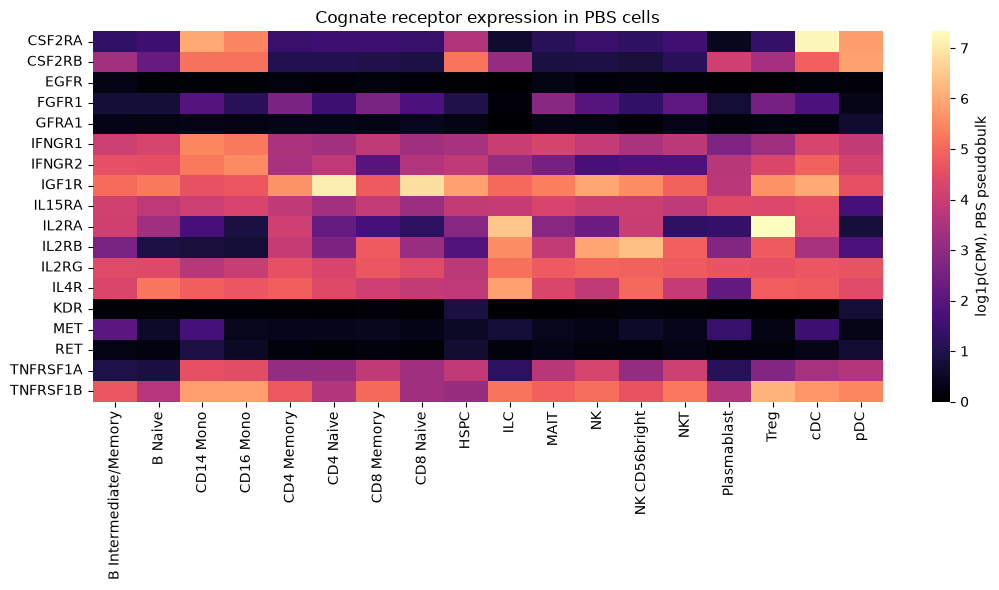

cell_type,B Intermediate/Memory,B Naive,CD14 Mono,CD16 Mono,CD4 Memory,CD4 Naive,CD8 Memory,CD8 Naive,HSPC,ILC,MAIT,NK,NK CD56bright,NKT,Plasmablast,Treg,cDC,pDC
CSF2RA,1.30,1.49,5.99,5.46,1.40,1.51,1.51,1.39,3.59,0.66,1.17,1.43,1.27,1.53,0.40,1.37,7.22,5.83
CSF2RB,3.31,2.26,5.16,5.17,1.04,1.04,0.99,0.91,5.21,3.11,0.87,0.89,0.81,1.16,4.10,3.38,4.87,5.89
EGFR,0.26,0.11,0.09,0.11,0.19,0.12,0.16,0.13,0.08,0.00,0.28,0.14,0.15,0.10,0.00,0.04,0.18,0.12
FGFR1,0.77,0.75,1.90,1.16,2.61,1.49,2.55,1.77,0.97,0.13,2.88,1.96,1.31,2.11,0.73,2.53,1.75,0.34
GFRA1,0.29,0.24,0.27,0.25,0.33,0.32,0.27,0.40,0.24,0.00,0.26,0.23,0.13,0.32,0.15,0.21,0.21,0.64
IFNGR1,4.05,4.24,5.47,5.28,3.49,3.34,3.82,3.26,3.42,3.99,4.22,3.92,3.44,3.77,2.69,3.25,4.24,3.88
IFNGR2,4.58,4.52,5.30,5.55,3.43,3.80,1.99,3.62,3.86,3.10,2.53,1.67,1.80,1.79,3.69,4.30,4.92,4.16
IGF1R,5.07,5.28,4.60,4.71,5.68,7.09,4.79,6.85,5.88,5.03,5.37,5.98,5.57,4.92,3.75,5.65,6.02,4.54
IL15RA,4.15,3.80,4.05,4.29,3.83,3.33,3.91,3.22,3.88,3.93,4.27,4.04,4.02,3.78,4.39,4.36,4.50,1.63
IL2RA,4.10,3.28,1.67,0.88,4.09,2.22,1.65,1.21,2.86,6.46,2.84,2.36,4.01,1.27,1.37,7.33,4.44,0.78


In [9]:
# gene-level receptor expression: mean over donors of log1p(CPM)
receptor_gene_expr = pd.DataFrame({ct: e.mean(axis=0) for ct, e in pb_expr.items()}).T
receptor_gene_expr.index.name = "cell_type"


def receptor_score(how):
    out = {}
    for lig, genes in RECEPTORS.items():
        g = [x for x in genes if x in receptor_gene_expr.columns]
        out[lig] = receptor_gene_expr[g].mean(axis=1) if how == "mean" else receptor_gene_expr[g].min(axis=1)
    return pd.DataFrame(out)


rec_mean, rec_min = receptor_score("mean"), receptor_score("min")

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(receptor_gene_expr.T, cmap="magma", ax=ax, cbar_kws={"label": "log1p(CPM), PBS pseudobulk"})
ax.set_title("Cognate receptor expression in PBS cells"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout()
plt.show()
receptor_gene_expr.T.round(2)

### Correlation across all ligand × cell-type pairs

Spearman ρ (primary) and Pearson r on log1p(DE count) / energy distance, over all 13 × 18 pairs with data.
Because the two ligand groups differ strongly in both receptor level and response, the pooled correlation partly
reflects that two-group split. The **within-group** correlations test whether response follows receptor level
*within* the receptor-rich ligands.

In [10]:
pairs = resp[~resp["ligand"].str.startswith("PBS")].copy()
pairs["receptor_mean"] = [rec_mean.loc[ct, lig] for lig, ct in zip(pairs["ligand"], pairs["cell_type"])]
pairs["receptor_min"] = [rec_min.loc[ct, lig] for lig, ct in zip(pairs["ligand"], pairs["cell_type"])]
pairs["log1p_n_de"] = np.log1p(pairs["n_de"])
pairs.to_csv(os.path.join(OUT_DIR, "09_receptor_vs_response.csv"), index=False)

corr_rows = []
for rec_col in ["receptor_mean", "receptor_min"]:
    for metric in ["log1p_n_de", "e_distance"]:
        for subset, d in [("all pairs", pairs), ("receptor-rich only", pairs[pairs["group"] == "receptor-rich"]),
                          ("receptor-poor only", pairs[pairs["group"] == "receptor-poor"])]:
            rho, p_rho = spearmanr(d[rec_col], d[metric])
            r, p_r = pearsonr(d[rec_col], d[metric])
            corr_rows.append({"receptor score": rec_col, "response": metric, "pairs": subset, "n": len(d),
                              "spearman_rho": rho, "p_spearman": p_rho, "pearson_r": r, "p_pearson": p_r})
corr = pd.DataFrame(corr_rows)
corr.round(4)

,receptor score,response,pairs,n,spearman_rho,p_spearman,pearson_r,p_pearson
0,receptor_mean,log1p_n_de,all pairs,206,0.5489,0.0000,0.5524,0.0000
1,receptor_mean,log1p_n_de,receptor-rich only,98,0.3423,0.0006,0.3343,0.0008
2,receptor_mean,log1p_n_de,receptor-poor only,108,0.2220,0.0209,0.2819,0.0031
3,receptor_mean,e_distance,all pairs,206,0.5276,0.0000,0.4075,0.0000
4,receptor_mean,e_distance,receptor-rich only,98,0.2215,0.0284,0.2103,0.0377
5,receptor_mean,e_distance,receptor-poor only,108,0.2439,0.0110,0.1258,0.1945
6,receptor_min,log1p_n_de,all pairs,206,0.5250,0.0000,0.4880,0.0000
7,receptor_min,log1p_n_de,receptor-rich only,98,0.3180,0.0014,0.3164,0.0015
8,receptor_min,log1p_n_de,receptor-poor only,108,0.2071,0.0315,0.2799,0.0034
9,receptor_min,e_distance,all pairs,206,0.4977,0.0000,0.3314,0.0000


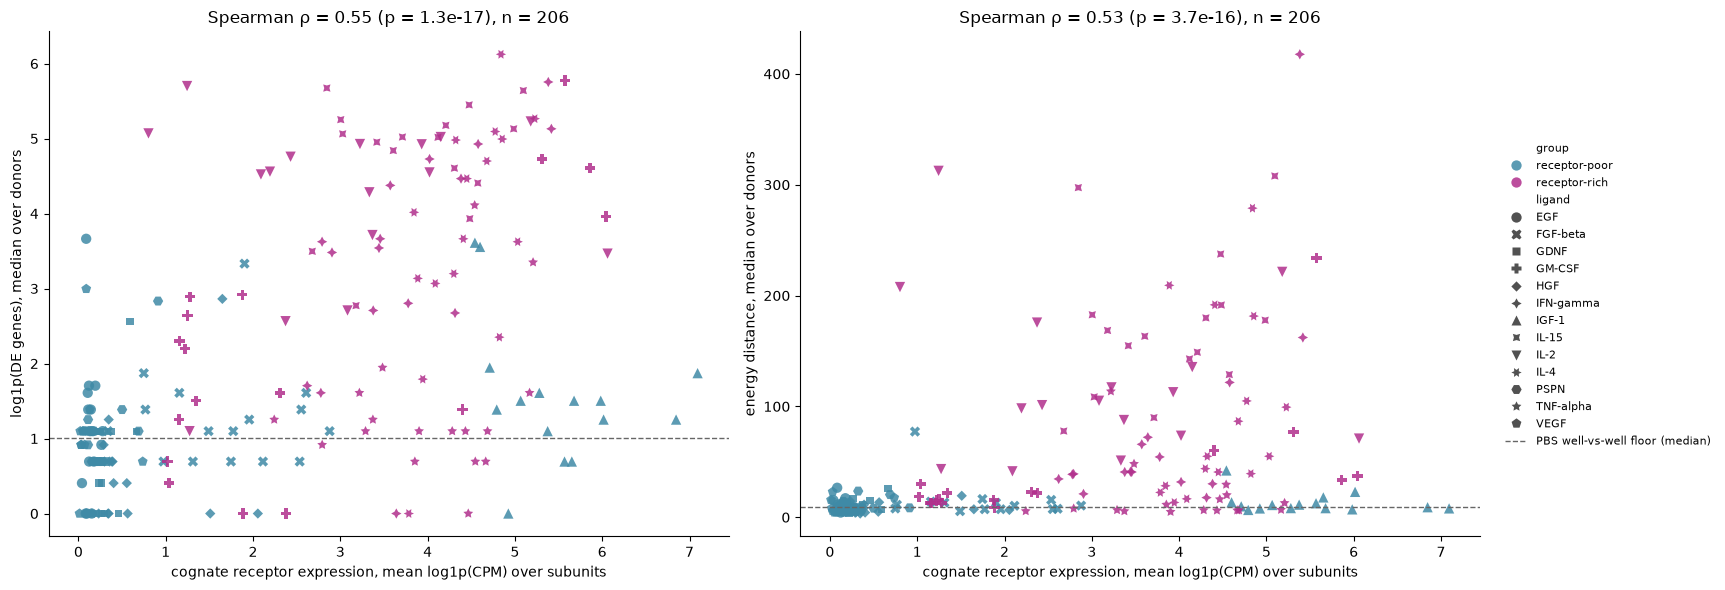

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, metric, ylab in [(axes[0], "log1p_n_de", "log1p(DE genes), median over donors"),
                         (axes[1], "e_distance", "energy distance, median over donors")]:
    sns.scatterplot(data=pairs, x="receptor_mean", y=metric, hue="group", palette=GROUP_COLORS,
                    style="ligand", s=55, ax=ax, edgecolor="none", alpha=0.85)
    f = floor[metric if metric == "e_distance" else "n_de"].median()
    ax.axhline(np.log1p(f) if metric == "log1p_n_de" else f, color="0.4", ls="--", lw=1, label="PBS well-vs-well floor (median)")
    c = corr[(corr["receptor score"] == "receptor_mean") & (corr["response"] == metric) & (corr["pairs"] == "all pairs")].iloc[0]
    ax.set_title(f"Spearman ρ = {c.spearman_rho:.2f} (p = {c.p_spearman:.1e}), n = {c.n}")
    ax.set_xlabel("cognate receptor expression, mean log1p(CPM) over subunits")
    ax.set_ylabel(ylab)
    ax.legend().remove()
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False, fontsize=8)
sns.despine()
plt.tight_layout()
plt.show()

## 4. What does the 06 model predict for these ligands?

Of the 13 ligands, the model was trained on **FGF-beta, GM-CSF, IL-4, IL-2** and on **IL-15 for Donor8 only**.
**EGF, HGF, IGF-1, VEGF, GDNF, PSPN, TNF-alpha and IFN-gamma were never seen**; for these the model predicts
from their ESM2 embedding alone (zero-shot). So the question for the receptor-poor ligands is: given only a protein
embedding, does the model predict "nothing happens" (correct, since PBMCs lack the receptor) or a sizeable effect?

`compute_e_distance` includes the zero self-distances (a V-statistic), so it is biased upwards by roughly
(σ_X + σ_Y)/n. Every comparison within a donor × cell type therefore uses the same n: observed, predicted and both floors.

Observed and predicted responses are both measured in the model's 100-PC space (from `cf.adata`), for its 4 donors,
per cell type. The predicted cells carry the cell type of the control cell they were generated from.

In [12]:
import jax
from cellflow.model import CellFlow
import cellflow.preprocessing as cfpp

print(jax.devices())
cf = CellFlow.load(MODEL_PATH)
ref = cf.adata                        # 06 training data, with X_pca and the PCA used by the model
MODEL_DONORS = sorted(ref.obs["donor"].unique())
TRAINED = set(ref.obs.loc[~ref.obs["is_control"], "cytokine"].unique())
status = {l: ("trained" if l in TRAINED else "unseen (zero-shot)") for l in LIGANDS}
status["IL-15"] = "trained for Donor8 only"
pd.Series(status, name="status in 06 model").to_frame()

[CudaDevice(id=0)]


,status in 06 model
EGF,unseen (zero-shot)
FGF-beta,trained
HGF,unseen (zero-shot)
IGF-1,unseen (zero-shot)
VEGF,unseen (zero-shot)
GDNF,unseen (zero-shot)
PSPN,unseen (zero-shot)
GM-CSF,trained
IL-15,trained for Donor8 only
TNF-alpha,unseen (zero-shot)


In [13]:
N_SRC, N_CMP = 2000, 500
rng = np.random.default_rng(SEED)

# source (model input) and disjoint reference PBS cells per donor, from the model's own training object
src_idx, cmp_idx = {}, {}
for d in MODEL_DONORS:
    pbs = np.flatnonzero((ref.obs["donor"] == d).to_numpy() & ref.obs["is_control"].to_numpy())
    perm = rng.permutation(pbs)
    src_idx[d], cmp_idx[d] = np.sort(perm[:N_SRC]), perm[N_SRC:]

src = ref[np.concatenate([src_idx[d] for d in MODEL_DONORS])].copy()   # keeps .uns (ESM2 + donor embeddings)
src.obs["condition"] = src.obs["donor"].astype(str) + "_PBS"
cov = pd.DataFrame([(d, l) for d in MODEL_DONORS for l in LIGANDS], columns=["donor", "cytokine"])
cov["is_control"] = False
cov["condition"] = cov["donor"] + "_" + cov["cytokine"]
for col in ["donor", "cytokine"]:
    cov[col] = cov[col].astype("category")

t0 = time.perf_counter()
preds = cf.predict(adata=src, sample_rep="X_pca", condition_id_key="condition", covariate_data=cov)
print(f"{len(preds)} conditions predicted in {time.perf_counter() - t0:.0f} s")

[                                        ] | 0% Completed | 303.67 us

[########################################] | 100% Completed | 101.46 ms

[                                        ] | 0% Completed | 286.05 us

[########################################] | 100% Completed | 101.42 ms

[                                        ] | 0% Completed | 162.90 us

[########################################] | 100% Completed | 101.35 ms

52 conditions predicted in 783 s


In [14]:
# observed ligand cells for the 4 model donors, projected into the model's PCA space
obs_cells = adata[adata.obs["donor"].isin(MODEL_DONORS).to_numpy() & adata.obs["cytokine"].isin(LIGANDS).to_numpy()].copy()
obs_cells = obs_cells[:, ref.var_names].copy()
cfpp.project_pca(query_adata=obs_cells, ref_adata=ref)

src_ct = {d: src.obs.loc[src.obs["donor"] == d, "cell_type"].astype(str).to_numpy() for d in MODEL_DONORS}
ref_pca = np.asarray(ref.obsm["X_pca"])
ref_ct = ref.obs["cell_type"].astype(str).to_numpy()
ref_well = ref.obs["bc1_well"].astype(str).to_numpy()

rng = np.random.default_rng(SEED)
rows = []
for d in MODEL_DONORS:
    cmp_d = cmp_idx[d]
    for ct in sorted(set(src_ct[d])):
        cmp_ct = cmp_d[ref_ct[cmp_d] == ct]
        src_ct_pca = np.asarray(src[(src.obs["donor"] == d).to_numpy()].obsm["X_pca"])[src_ct[d] == ct]
        # floor: model input cells vs disjoint PBS cells (what a "no effect" prediction scores)
        n = min(len(src_ct_pca), len(cmp_ct), N_CMP)
        if n < N_MIN:
            continue
        cmp_s = ref_pca[rng.choice(cmp_ct, n, replace=False)]
        rows.append({"donor": d, "cell_type": ct, "ligand": "PBS (floor)", "source": "floor",
                     "e_distance": float(compute_e_distance(src_ct_pca[rng.choice(len(src_ct_pca), n, replace=False)], cmp_s))})
        # well floor: one PBS well vs the donor's other PBS wells (reference pool only). Capped at the same n as the
        # other comparisons of this donor x cell type: compute_e_distance is a V-statistic whose positive bias
        # (~(σ_X + σ_Y)/n) depends on n, so floors are only comparable at matched n.
        for w in np.unique(ref_well[cmp_ct]):
            a, b = cmp_ct[ref_well[cmp_ct] == w], cmp_ct[ref_well[cmp_ct] != w]
            m = min(len(a), len(b), n)
            if m >= N_MIN:
                rows.append({"donor": d, "cell_type": ct, "ligand": "PBS well (floor)", "source": "floor_well", "well": w,
                             "e_distance": float(compute_e_distance(ref_pca[rng.choice(a, m, replace=False)],
                                                                    ref_pca[rng.choice(b, m, replace=False)]))})
        for lig in LIGANDS:
            p = np.squeeze(preds[f"{d}_{lig}"])[src_ct[d] == ct]
            o = obs_cells[(obs_cells.obs["donor"] == d).to_numpy() & (obs_cells.obs["cytokine"] == lig).to_numpy()
                          & (obs_cells.obs["cell_type"].astype(str) == ct).to_numpy()].obsm["X_pca"]
            m = min(n, len(p), len(o))
            if m < N_MIN:
                continue
            c = cmp_s[:m]
            rows.append({"donor": d, "cell_type": ct, "ligand": lig, "source": "predicted",
                         "e_distance": float(compute_e_distance(p[rng.choice(len(p), m, replace=False)], c))})
            rows.append({"donor": d, "cell_type": ct, "ligand": lig, "source": "observed",
                         "e_distance": float(compute_e_distance(np.asarray(o)[rng.choice(len(o), m, replace=False)], c))})

model_resp = pd.DataFrame(rows)
model_resp.to_csv(os.path.join(OUT_DIR, "09_model_vs_observed.csv"), index=False)
per_donor = model_resp.groupby(["ligand", "cell_type", "source", "donor"])["e_distance"].median()   # wells -> donor
mr = per_donor.groupby(level=["ligand", "cell_type", "source"]).median().unstack("source")
mr_floor = mr.loc["PBS (floor)", "floor"]
mr_floor_well = mr.loc["PBS well (floor)", "floor_well"]
FLOORS = ["PBS (floor)", "PBS well (floor)"]

In [15]:
lig_table = mr.drop(index=FLOORS, level="ligand")[["observed", "predicted"]].groupby(level="ligand").median()
lig_table["random floor"] = mr_floor.median()
lig_table["well floor"] = mr_floor_well.median()
lig_table["pred / obs"] = lig_table["predicted"] / lig_table["observed"]
lig_table["group"] = lig_table.index.map(GROUP)
lig_table["model status"] = lig_table.index.map(status)
lig_table["obs / well floor"] = lig_table["observed"] / lig_table["well floor"]
lig_table["pred / well floor"] = lig_table["predicted"] / lig_table["well floor"]
lig_table = lig_table.loc[LIGANDS, ["group", "model status", "observed", "predicted", "well floor", "random floor",
                                    "obs / well floor", "pred / well floor", "pred / obs"]]
lig_table.round(3)

source,group,model status,observed,predicted,well floor,random floor,obs / well floor,pred / well floor,pred / obs
ligand,,,,,,,,,
EGF,receptor-poor,unseen (zero-shot),23.353,16.511,21.336,13.094,1.095,0.774,0.707
FGF-beta,receptor-poor,trained,23.693,16.864,21.336,13.094,1.110,0.790,0.712
HGF,receptor-poor,unseen (zero-shot),19.571,15.503,21.336,13.094,0.917,0.727,0.792
IGF-1,receptor-poor,unseen (zero-shot),28.866,18.257,21.336,13.094,1.353,0.856,0.632
VEGF,receptor-poor,unseen (zero-shot),19.150,16.588,21.336,13.094,0.898,0.777,0.866
GDNF,receptor-poor,unseen (zero-shot),21.474,19.215,21.336,13.094,1.006,0.901,0.895
PSPN,receptor-poor,unseen (zero-shot),21.045,18.773,21.336,13.094,0.986,0.880,0.892
GM-CSF,receptor-rich,trained,53.013,44.219,21.336,13.094,2.485,2.072,0.834
IL-15,receptor-rich,trained for Donor8 only,207.260,124.738,21.336,13.094,9.714,5.846,0.602


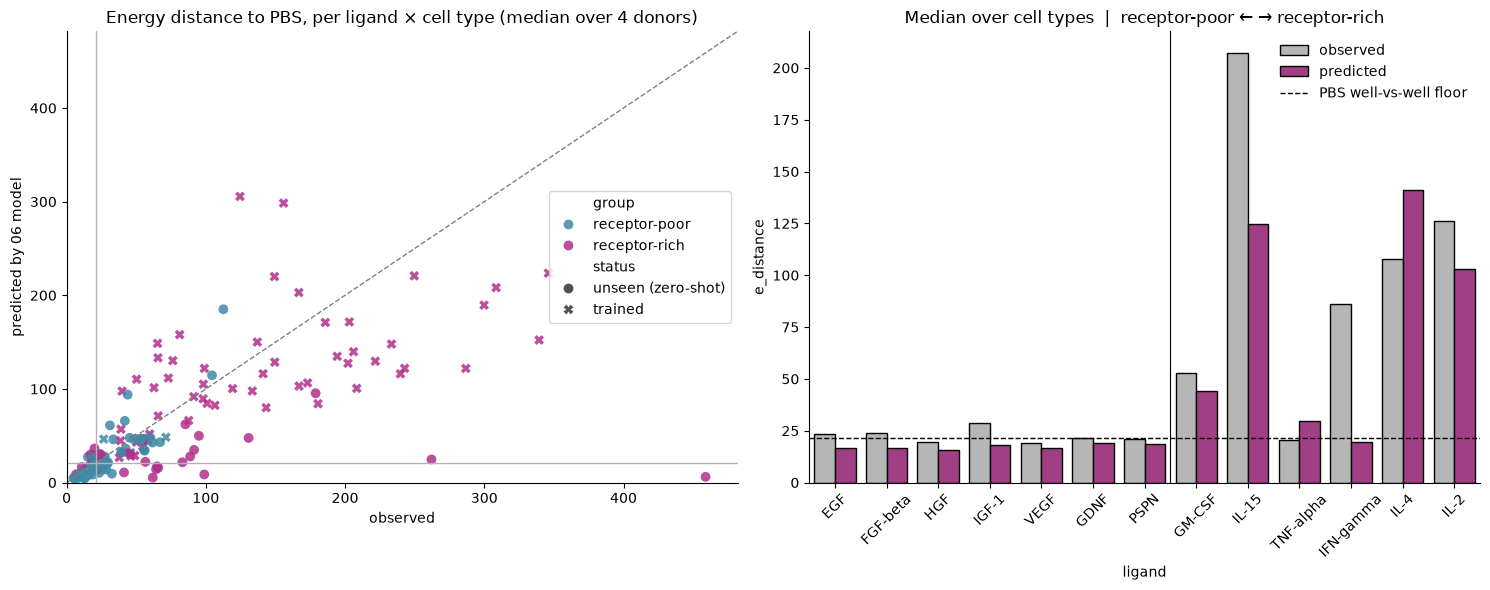

In [16]:
d = mr.drop(index=FLOORS, level="ligand").reset_index()
d["group"] = d["ligand"].map(GROUP)
d["status"] = d["ligand"].map(status).str.replace(" for Donor8 only", "")
lim = [0, max(d["observed"].max(), d["predicted"].max()) * 1.05]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(data=d, x="observed", y="predicted", hue="group", palette=GROUP_COLORS, style="status",
                s=50, ax=axes[0], edgecolor="none", alpha=0.85)
axes[0].plot(lim, lim, color="0.5", lw=1, ls="--")
axes[0].axhline(mr_floor_well.median(), color="0.7", lw=1); axes[0].axvline(mr_floor_well.median(), color="0.7", lw=1)
axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_title("Energy distance to PBS, per ligand × cell type (median over 4 donors)")
axes[0].set_xlabel("observed"); axes[0].set_ylabel("predicted by 06 model")

long = lig_table.reset_index().melt(id_vars=["ligand", "group"], value_vars=["observed", "predicted"],
                                     var_name="source", value_name="e_distance")
sns.barplot(data=long, x="ligand", y="e_distance", hue="source", order=LIGANDS,
            palette={"observed": "#B6B6B6", "predicted": "#B12F8C"}, edgecolor="black", ax=axes[1])
axes[1].axhline(mr_floor_well.median(), color="k", ls="--", lw=1, label="PBS well-vs-well floor")
axes[1].axvline(len(POOR) - 0.5, color="k", lw=0.8)
axes[1].set_title("Median over cell types  |  receptor-poor ← → receptor-rich")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend(frameon=False)
sns.despine()
plt.tight_layout()
plt.show()

In [17]:
summary = lig_table.groupby(["group", "model status"])[["observed", "predicted", "well floor"]].median()
summary["pred / obs"] = summary["predicted"] / summary["observed"]
summary.round(3)

source                                 observed  predicted  well floor  \
group         model status                                               
receptor-poor trained                    23.693     16.864      21.336   
              unseen (zero-shot)         21.260     17.423      21.336   
receptor-rich trained                   107.916    103.206      21.336   
              trained for Donor8 only   207.260    124.738      21.336   
              unseen (zero-shot)         53.327     24.515      21.336   

source                                 pred / obs  
group         model status                         
receptor-poor trained                       0.712  
              unseen (zero-shot)            0.820  
receptor-rich trained                       0.956  
              trained for Donor8 only       0.602  
              unseen (zero-shot)            0.460

## Conclusion

**1. The receptor-poor ligands are null in PBMCs.** Each cytokine sits in one barcoding well per donor, so the right
null is one PBS well vs the others (the *well floor*: median energy distance 9.2 in the 50-PC space, 1.75 DE genes).
Against it, **EGF, FGF-beta, HGF, IGF-1, VEGF, GDNF and PSPN exceed 2× the floor in 0–1 of their 15–16 cell types**
(energy distance) and in 0–1 cell types for DE genes. Their median DE count is 0.5–3.5 genes. Against a naive PBS-vs-PBS
split (random floor 1.7) they would have looked like weak responders in almost every cell type. That difference is
purely well-to-well technical variation, so ligand-vs-PBS comparisons in this dataset need the well-level null.

**2. The receptor-rich ligands mostly respond, with one clear exception.**
* **IL-15, IL-2, IFN-γ and IL-4** respond in 14–16 of 16 cell types (median 35–150 DE genes).
* **GM-CSF** responds in about half the cell types (9/17), consistent with CSF2RA being high only in myeloid cells.
* **TNF-α is effectively null** (2/17 cell types; median 2 DE genes), even though TNFRSF1A/1B are well expressed.
* At the other end, **IGF1R is well expressed in T cells** (log1p CPM 5–7), yet IGF-1 does nothing.

Receptor mRNA is therefore necessary but not sufficient. Ligand activity under these culture conditions, and
receptor protein and signalling competence, also matter.

**3. Receptor expression correlates with response magnitude**, with Spearman ρ = 0.55 for DE count and 0.53 for
energy distance (206 ligand × cell-type pairs, p < 10⁻¹⁵). Much of that is the two-group split. Within the receptor-rich
ligands, ρ = 0.34 (DE, p = 6×10⁻⁴) and 0.22 (energy distance, p = 0.03). Using the scarcest subunit instead of the mean
gives the same picture.

**4. The model.** In the model's own 100-PC space, with every comparison at matched n (the well floor there is 21.3):

| | observed / well floor | predicted / well floor |
|---|---|---|
| receptor-poor, 6 unseen + FGF-beta (trained) | 0.9–1.35 | 0.73–0.90 |
| IFN-γ (receptor-rich, unseen) | **4.0** | **0.9** |
| TNF-α (receptor-rich, unseen) | 0.97 | 1.38 |
| trained receptor-rich (GM-CSF, IL-2, IL-4) | 2.5–5.9 | 2.1–6.6 |
| IL-15 (trained for Donor8 only) | 9.7 | 5.8 |

**The model does not predict a substantial effect for the receptor-poor ligands. That matches the data, but for the
wrong reason.** Six of the seven were never seen in training, and the model predicts a near-floor response for *every*
unseen ligand. The decisive case is IFN-γ: its receptor is abundant, and it produces one of the largest observed
responses (4× the floor, 16/16 cell types). The model predicts nothing for it. From ESM2 alone, the model cannot tell
"a ligand whose receptor is on these cells" from "a ligand whose receptor is absent". It defaults to "no effect",
which happens to be correct for the receptor-poor group.

**Why this matters for the project.** Receptor competence is the dominant factor in whether PBMCs respond at all. The
current model has no access to it, so for unseen ligands its predictions carry no receptor information. This is the
motivating result: a model that conditioned on receptor expression of the target cells would get IFN-γ and the growth
factors right for the right reason.

**Caveats.**
* The pseudobulk cell-type annotation is Parse's release-time version. It matches the HF labels closely for myeloid,
  B and NK cells but less well for T-cell subsets and ILCs (count correlation 0.14 for ILC), so their receptor values
  are approximate.
* GFRA4 is not in the gene annotation, so PSPN is scored on RET alone.
* The model is 06's, trained on 20 cytokines and 4 donors.
